# Model 1 · 3. Evaluasi model deteksi

Model: `models/deteksi_yolov8s_v3_bh_640.pt` (YOLOv8s, dilatih di Colab dengan notebook 2).

| Ujian | Isi |
|---|---|
| **test lama** | 48 foto `data/deteksi/test`, label rapi |
| **test baru** | 108 foto `data/deteksi_bh/test` berisi Blackheads, tidak ikut training |

Ukuran: **mAP50** (rata-rata presisi pada IoU 0,5), **precision** (berapa kotak model yang benar), **recall** (berapa jerawat
yang ditemukan), dan **recall per jenis** di test baru. Jalan di CPU, sekitar 2-3 menit. *Bukan alat diagnosis medis.*

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
while not (ROOT / 'models').exists() or not (ROOT / 'data').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Jalankan notebook dari dalam folder proyek FINAL')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
DATA = ROOT / 'data'
print('folder proyek:', ROOT)

import json
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from ultralytics import YOLO

SIMPAN = ROOT / 'hasil' / 'model1'
SIMPAN.mkdir(parents=True, exist_ok=True)
model = YOLO(ROOT / 'models' / 'deteksi_yolov8s_v3_bh_640.pt')
print('parameter model:', sum(p.numel() for p in model.model.parameters()) // 1000, 'ribu')

folder proyek: C:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL


parameter model: 11135 ribu


## 1. mAP50, precision, recall

In [2]:
UJIAN = {'test lama': DATA / 'deteksi' / 'test', 'test baru (Blackheads)': DATA / 'deteksi_bh' / 'test'}
tabel = []
for nama, folder in UJIAN.items():
    yaml = SIMPAN / f"uji_{nama.split()[1]}.yaml"
    yaml.write_text(f"path: {folder.as_posix()}\ntrain: images\nval: images\nnc: 1\nnames: ['Acne']\n")
    r = model.val(data=str(yaml), split='val', imgsz=640, batch=8, device='cpu', plots=False, verbose=False,
                  project=str(SIMPAN), name='val', exist_ok=True)
    tabel.append({'ujian': nama, 'foto': len(list((folder / 'images').glob('*'))), 'mAP50': r.box.map50,
                  'mAP50-95': r.box.map, 'precision': r.box.mp, 'recall': r.box.mr})
tabel = pd.DataFrame(tabel).round(3)
tabel.to_csv(SIMPAN / 'hasil_ujian.csv', index=False)
print(tabel.to_string(index=False))

Ultralytics 8.4.193  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core Ultra 5 125U)


Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 117.8±47.1 MB/s, size: 38.1 KB)


val: Scanning C:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL\data\deteksi\test\labels... 48 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 48/48 699.7it/s 0.1s

val: New cache created: C:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL\data\deteksi\test\labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 16% ━━────────── 1/6 6.5s/it 2.0s<32.7s

... (25 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 1.9s/it 26.7s

                   all        108       1226      0.269      0.348      0.181     0.0591


Speed: 1.4ms preprocess, 228.8ms inference, 0.0ms loss, 5.5ms postprocess per image


                 ujian  foto  mAP50  mAP50-95  precision  recall
             test lama    48  0.651     0.288      0.708   0.578
test baru (Blackheads)   108  0.181     0.059      0.269   0.348


## 2. Recall per jenis di test baru
Sebuah jerawat dihitung ditemukan kalau ada kotak model yang IoU-nya >= 0,2 atau titik tengahnya di dalam kotak label (keyakinan 0,25).

In [3]:
def ke_xyxy(xc, yc, w, h, W, H):
    return ((xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H)


def iou(a, b):
    x0, y0, x1, y1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    irisan = max(0, x1 - x0) * max(0, y1 - y0)
    return irisan / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - irisan + 1e-9)


def cocok(t, l):
    cx, cy = (t[0] + t[2]) / 2, (t[1] + t[3]) / 2
    return iou(t, l) >= 0.2 or (l[0] <= cx <= l[2] and l[1] <= cy <= l[3])


jenis = json.load(open(DATA / 'deteksi_bh' / 'jenis_asli_test.json'))
ketemu, total = Counter(), Counter()
nama = sorted(jenis)
for i in range(0, len(nama), 16):
    hasil = model.predict([str(DATA / 'deteksi_bh' / 'test' / 'images' / n) for n in nama[i:i + 16]],
                          imgsz=640, conf=0.25, iou=0.45, device='cpu', verbose=False)
    for n, r in zip(nama[i:i + 16], hasil):
        H, W = r.orig_shape
        tebak = r.boxes.xyxy.tolist()
        for k, *b in jenis[n]:
            total[k] += 1
            ketemu[k] += any(cocok(t, ke_xyxy(*b, W, H)) for t in tebak)
rj = pd.DataFrame({'jumlah': total, 'ditemukan': ketemu}).fillna(0).astype(int)
rj['recall'] = (rj.ditemukan / rj.jumlah).round(3)
print(rj.sort_values('jumlah', ascending=False).to_string())

           jumlah  ditemukan  recall
Blackhead     448        109   0.243
Papular       300        131   0.437
Acne          187         74   0.396
Purulent      129         80   0.620
Whitehead     122         13   0.107
Cystic         40         22   0.550


Blackheads dan Whiteheads paling jarang ditemukan, karena berupa titik sangat kecil di foto beresolusi rendah.
Itu sebabnya model ini dipilih: recall Blackheads-nya paling tinggi di antara model yang dicoba.

## 3. Perbandingan dengan model lain (dari percobaan di Colab)

In [4]:
banding = pd.DataFrame([
    ('v1 lama, YOLOv8n @640', 0.649, 0.070, 0.170),
    ('v3 YOLOv8n @640 (les tambahan)', 0.663, 0.132, 0.210),
    ('v3 YOLOv8s @640 (DIPAKAI)', 0.651, 0.181, 0.243),
    ('v3 YOLOv8n @960', 0.614, 0.148, 0.156),
    ('v2 (gagal, data baru dicampur semua)', 0.585, None, 0.041),
], columns=['model', 'test lama mAP50', 'test baru mAP50', 'recall Blackheads'])
print(banding.to_string(index=False))

                               model  test lama mAP50  test baru mAP50  recall Blackheads
               v1 lama, YOLOv8n @640            0.649            0.070              0.170
      v3 YOLOv8n @640 (les tambahan)            0.663            0.132              0.210
           v3 YOLOv8s @640 (DIPAKAI)            0.651            0.181              0.243
                     v3 YOLOv8n @960            0.614            0.148              0.156
v2 (gagal, data baru dicampur semua)            0.585              NaN              0.041


## 4. Kurva training
Log training model YOLOv8s ada di Google Drive (`acne_det_runs/deteksi_v3_bh_v8s_640`). Kalau `results.csv`-nya disalin ke `riwayat_training/deteksi_v3_bh_v8s_640/`, kurvanya muncul di sini; kalau belum, yang ditampilkan adalah run sejenis (YOLOv8n, data yang sama).

log: riwayat_training\deteksi_v3_bh_640_yolov8n\results.csv


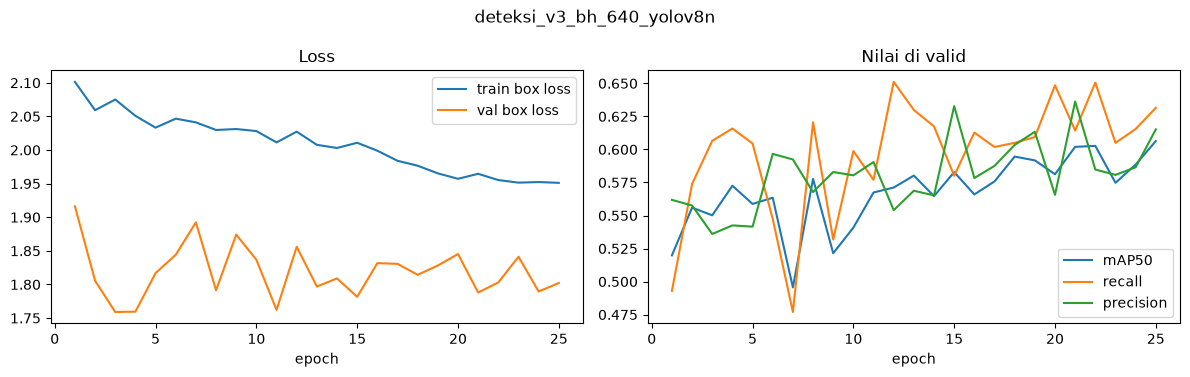

In [5]:
calon = [ROOT / 'riwayat_training' / 'deteksi_v3_bh_v8s_640' / 'results.csv',
         ROOT / 'riwayat_training' / 'deteksi_v3_bh_640_yolov8n' / 'results.csv']
csv = next(p for p in calon if p.exists())
log = pd.read_csv(csv); log.columns = log.columns.str.strip()
print('log:', csv.relative_to(ROOT))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(log.epoch, log['train/box_loss'], label='train box loss'); ax[0].plot(log.epoch, log['val/box_loss'], label='val box loss')
ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].set_title('Loss')
ax[1].plot(log.epoch, log['metrics/mAP50(B)'], label='mAP50'); ax[1].plot(log.epoch, log['metrics/recall(B)'], label='recall')
ax[1].plot(log.epoch, log['metrics/precision(B)'], label='precision'); ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].set_title('Nilai di valid')
plt.suptitle(csv.parent.name); plt.tight_layout(); plt.show()

## 5. Contoh hasil deteksi (hijau = label, merah = tebakan model)

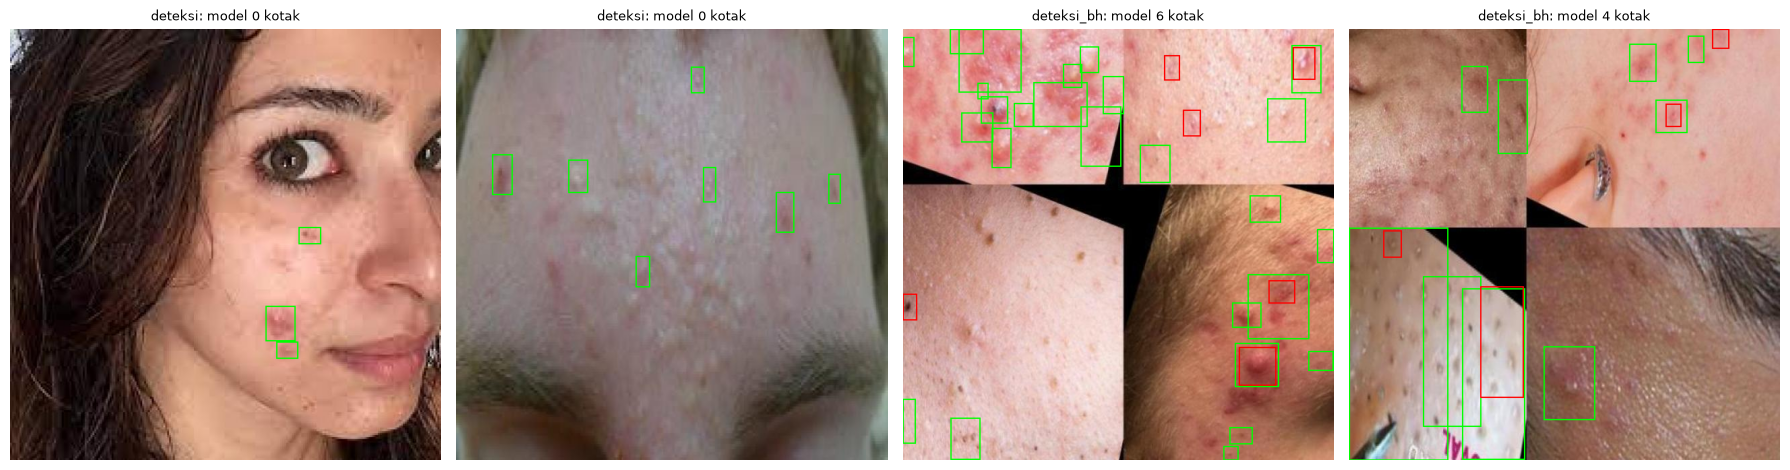

In [6]:
contoh = sorted((DATA / 'deteksi' / 'test' / 'images').glob('*'))[:2] + sorted((DATA / 'deteksi_bh' / 'test' / 'images').glob('*'))[:2]
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for a, g in zip(ax, contoh):
    im = Image.open(g).convert('RGB'); W, H = im.size; dr = ImageDraw.Draw(im)
    for t in (g.parent.parent / 'labels' / (g.stem + '.txt')).read_text().splitlines():
        if len(t.split()) >= 5:
            dr.rectangle(ke_xyxy(*map(float, t.split()[1:5]), W, H), outline=(0, 255, 0), width=2)
    r = model.predict(im, imgsz=640, conf=0.25, device='cpu', verbose=False)[0]
    for b in r.boxes.xyxy.tolist():
        dr.rectangle(b, outline=(255, 0, 0), width=2)
    a.imshow(im); a.axis('off'); a.set_title(f'{g.parent.parent.parent.name}: model {len(r.boxes)} kotak', fontsize=9)
plt.tight_layout(); plt.show()

## Kesimpulan
- Model 1 menemukan sekitar 60% jerawat di test lama (recall) dengan mAP50 sekitar 0,65.
- Blackheads dan Whiteheads masih jarang ditemukan (titik kecil di foto kecil).
- Model lebih besar dan gambar lebih besar (960) tidak menaikkan nilai secara berarti: batas utamanya **kualitas data**
  (resolusi foto rendah dan label tidak konsisten).